# EDA — 01. Composición y Estructura del Dataset Hillstrom

**Proyecto Final — Uplift Modeling | Licenciatura en Ciencia de Datos — CAECE**
**Autor:** Joaquin Tomas Lisotti · DNI 43422090
**Notebook:** `01_overview.ipynb`

---

## Objetivo y Alcance

Propósito exclusivo de este notebook: **entender la composición y estructura del dataset** antes de cualquier análisis estadístico.

**Se analiza:**
- Estructura y esquema (dimensiones, tipos, memoria)
- Diccionario completo de variables con rol y dominio
- Auditoría de calidad (nulos, duplicados, consistencia lógica)
- Balance de los grupos experimentales (diseño del RCT)
- Cardinalidad y composición de variables categóricas y binarias
- Rangos y escalas de variables numéricas
- Temporalidad embebida en el dataset

**No se analiza aquí:**
- Distribuciones individuales (análisis univariado)
- Relaciones entre variables (análisis bivariado / multivariado)

---

## Contexto del Experimento

El **MineThatData E-Mail Analytics And Data Mining Challenge** (Hillstrom, 2008) es el benchmark estándar en la literatura de uplift modeling, citado en decenas de papers en KDD, ECML y revistas de marketing analítico.

### Diseño experimental (RCT)

Un e-commerce de indumentaria seleccionó **64.000 clientes activos** (al menos una compra en los últimos 12 meses) y los asignó **aleatoriamente** a tres grupos:

| Grupo | Tratamiento | Tamaño aprox. |
|-------|-------------|----------------|
| `Mens E-Mail` | Email promocionando productos masculinos | ≈21.000 |
| `Womens E-Mail` | Email promocionando productos femeninos | ≈21.000 |
| `No E-Mail` | Control — sin comunicación | ≈21.000 |

Las interacciones se registraron durante las **dos semanas posteriores** al envío, capturando tres outcomes: `visit` (binario), `conversion` (binario) y `spend` (continuo USD).

La asignación aleatoria garantiza independencia entre tratamiento y características del cliente, lo que permite estimar el **efecto causal incremental (CATE)** — fundamento estadístico del uplift modeling.

> Hillstrom, K. (2008). *The MineThatData E-Mail Analytics And Data Mining Challenge*. MineThatData Blog.

## 1. Setup

In [1]:
import os
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

try:
    from scipy import stats
    HAS_SCIPY = True
except ImportError:
    HAS_SCIPY = False
    print("scipy no instalado — se omitirá el test chi²")

warnings.filterwarnings("ignore")

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("seaborn-whitegrid")

sns.set_palette("Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_colwidth", 80)

print("Setup completo.")

Setup completo.


## 2. Adquisición del Dataset

El dataset se descarga desde la fuente original del autor y se persiste en `data/raw/hillstrom.csv`.

In [2]:
BASE_DIR     = os.path.join("..", "..")
RAW_DIR      = os.path.join(BASE_DIR, "data", "raw")
DATASET_URL  = (
    "http://www.minethatdata.com/"
    "Kevin_Hillstrom_MineThatData_E-MailAnalytics_"
    "DataMiningChallenge_2008.03.20.csv"
)
DATASET_PATH = os.path.join(RAW_DIR, "hillstrom.csv")

os.makedirs(RAW_DIR, exist_ok=True)

if not os.path.exists(DATASET_PATH):
    print("Descargando dataset...")
    urllib.request.urlretrieve(DATASET_URL, DATASET_PATH)
    print(f"Guardado en: {DATASET_PATH}")
else:
    print(f"Dataset disponible: {DATASET_PATH}")

df = pd.read_csv(DATASET_PATH)
print(f"\nDataset cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas")
df.head(5)

Dataset disponible: ../../data/raw/hillstrom.csv

Dataset cargado: 64,000 filas × 12 columnas


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.4400,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0000
1,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,0,0,0.0000
2,7,2) $100 - $200,180.6500,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0000
3,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0000
4,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0000


## 3. Inspección Inicial

In [3]:
mem = df.memory_usage(deep=True).sum()
n_cells = df.shape[0] * df.shape[1]
n_nulls = df.isnull().sum().sum()

print("=" * 58)
print("  INFORMACIÓN GENERAL DEL DATASET")
print("=" * 58)
print(f"  Filas              : {df.shape[0]:,}")
print(f"  Columnas           : {df.shape[1]}")
print(f"  Celdas totales     : {n_cells:,}")
print(f"  Memoria total      : {mem / 1024:.1f} KB  ({mem / 1024**2:.3f} MB)")
print(f"  Celdas nulas       : {n_nulls:,}")
print(f"  Densidad           : {(1 - n_nulls / n_cells) * 100:.4f}%")
print("=" * 58)

  INFORMACIÓN GENERAL DEL DATASET
  Filas              : 64,000
  Columnas           : 12
  Celdas totales     : 768,000
  Memoria total      : 20503.1 KB  (20.023 MB)
  Celdas nulas       : 0
  Densidad           : 100.0000%


In [4]:
col_info = pd.DataFrame({
    "Columna" : df.columns.tolist(),
    "dtype"   : df.dtypes.values.astype(str).tolist(),
    "No nulos": df.notna().sum().values.tolist(),
    "Nulos"   : df.isnull().sum().values.tolist(),
    "% Nulos" : (df.isnull().mean() * 100).round(4).values.tolist(),
    "Únicos"  : [df[c].nunique() for c in df.columns],
    "Muestra" : [str(df[c].iloc[0]) for c in df.columns],
    "Mem(KB)" : (df.memory_usage(deep=True).values[1:] / 1024).round(2).tolist(),
}).set_index("Columna")

display(col_info.style.set_caption("Esquema completo de columnas"))

,dtype,No nulos,Nulos,% Nulos,Únicos,Muestra,Mem(KB)
Columna,,,,,,,
recency,int64,64000,0,0.000000,12,10,500.000000
history_segment,object,64000,0,0.000000,7,2) $100 - $200,4392.440000
history,float64,64000,0,0.000000,34833,142.44,500.000000
mens,int64,64000,0,0.000000,2,1,500.000000
womens,int64,64000,0,0.000000,2,0,500.000000
zip_code,object,64000,0,0.000000,3,Surburban,3987.410000
newbie,int64,64000,0,0.000000,2,0,500.000000
channel,object,64000,0,0.000000,3,Phone,3872.950000
segment,object,64000,0,0.000000,3,Womens E-Mail,4250.160000


## 4. Diccionario de Variables

| Variable | dtype | Rol | Naturaleza | Descripción | Dominio |
|----------|-------|-----|------------|-------------|---------|
| `recency` | int64 | Feature | Ordinal discreta | Meses desde la última compra | [1, 12] |
| `history_segment` | object | Feature | Categórica ordinal | Segmento de gasto histórico | 7 categorías |
| `history` | float64 | Feature | Continua | Gasto histórico total (USD) | > 0 |
| `mens` | int64 | Feature | Binaria | Compró productos masculinos históricamente | {0, 1} |
| `womens` | int64 | Feature | Binaria | Compró productos femeninos históricamente | {0, 1} |
| `zip_code` | object | Feature | Categórica nominal | Zona geográfica del cliente | {Rural, Surburban*, Urban} |
| `newbie` | int64 | Feature | Binaria | Cliente adquirido en el último año | {0, 1} |
| `channel` | object | Feature | Categórica nominal | Canal de compra histórico | {Phone, Web, Multichannel} |
| `segment` | object | **Tratamiento** | Categórica nominal | Grupo experimental asignado | {Mens E-Mail, Womens E-Mail, No E-Mail} |
| `visit` | int64 | **Outcome** | Binaria | Visitó el sitio en 2 semanas post-envío | {0, 1} |
| `conversion` | int64 | **Outcome** | Binaria | Realizó una compra en 2 semanas post-envío | {0, 1} |
| `spend` | float64 | **Outcome** | Continua ≥ 0 | Gasto en USD en 2 semanas post-envío | ≥ 0 |

> \* `"Surburban"` es un typo del dataset original (debería ser `"Suburban"`). Se preserva sin corrección en `raw`.

## 5. Clasificación de Variables por Rol y Tipo

In [5]:
SCHEMA = [
    {"Variable": "segment",         "Rol": "Tratamiento",  "Tipo": "Categórica nominal",  "N únicos": df["segment"].nunique()},
    {"Variable": "visit",           "Rol": "Outcome",      "Tipo": "Binaria",             "N únicos": df["visit"].nunique()},
    {"Variable": "conversion",      "Rol": "Outcome",      "Tipo": "Binaria",             "N únicos": df["conversion"].nunique()},
    {"Variable": "spend",           "Rol": "Outcome",      "Tipo": "Continua ≥ 0",        "N únicos": df["spend"].nunique()},
    {"Variable": "recency",         "Rol": "Feature",      "Tipo": "Ordinal discreta",    "N únicos": df["recency"].nunique()},
    {"Variable": "history_segment", "Rol": "Feature",      "Tipo": "Categórica ordinal",  "N únicos": df["history_segment"].nunique()},
    {"Variable": "history",         "Rol": "Feature",      "Tipo": "Continua",            "N únicos": df["history"].nunique()},
    {"Variable": "mens",            "Rol": "Feature",      "Tipo": "Binaria",             "N únicos": df["mens"].nunique()},
    {"Variable": "womens",          "Rol": "Feature",      "Tipo": "Binaria",             "N únicos": df["womens"].nunique()},
    {"Variable": "zip_code",        "Rol": "Feature",      "Tipo": "Categórica nominal",  "N únicos": df["zip_code"].nunique()},
    {"Variable": "newbie",          "Rol": "Feature",      "Tipo": "Binaria",             "N únicos": df["newbie"].nunique()},
    {"Variable": "channel",         "Rol": "Feature",      "Tipo": "Categórica nominal",  "N únicos": df["channel"].nunique()},
]

schema_df = pd.DataFrame(SCHEMA)

ROLE_STYLE = {
    "Tratamiento": "background-color:#fff3cd; font-weight:bold",
    "Outcome"    : "background-color:#d1e7dd; font-weight:bold",
    "Feature"    : "background-color:#f8f9fa",
}

display(
    schema_df.style
    .applymap(lambda v: ROLE_STYLE.get(v, ""), subset=["Rol"])
    .set_caption("Clasificación de variables — Amarillo: Tratamiento | Verde: Outcomes | Gris: Features")
    .hide(axis="index")
)

roles = schema_df["Rol"].value_counts()
tipos = schema_df["Tipo"].value_counts()
print()
print("Por rol:")
for r, n in roles.items():
    print(f"  {r:<15}: {n}")
print("\nPor tipo:")
for t, n in tipos.items():
    print(f"  {t:<22}: {n}")

Variable,Rol,Tipo,N únicos
segment,Tratamiento,Categórica nominal,3
visit,Outcome,Binaria,2
conversion,Outcome,Binaria,2
spend,Outcome,Continua ≥ 0,429
recency,Feature,Ordinal discreta,12
history_segment,Feature,Categórica ordinal,7
history,Feature,Continua,34833
mens,Feature,Binaria,2
womens,Feature,Binaria,2
zip_code,Feature,Categórica nominal,3



Por rol:
  Feature        : 8
  Outcome        : 3
  Tratamiento    : 1

Por tipo:
  Binaria               : 5
  Categórica nominal    : 3
  Continua ≥ 0          : 1
  Ordinal discreta      : 1
  Categórica ordinal    : 1
  Continua              : 1


## 6. Auditoría de Calidad de Datos

### 6.1 Valores Faltantes

In [6]:
null_df = pd.DataFrame({
    "Columna" : df.columns.tolist(),
    "No nulos": df.notna().sum().values.tolist(),
    "Nulos"   : df.isnull().sum().values.tolist(),
    "% Nulos" : (df.isnull().mean() * 100).round(6).values.tolist(),
}).reset_index(drop=True)

null_df["Estado"] = null_df["Nulos"].apply(
    lambda x: "Completo" if x == 0 else f"⚠ {x:,} nulos"
)

def color_estado(val):
    if val == "Completo":
        return "color:#198754; font-weight:bold"
    return "color:#dc3545; font-weight:bold"

display(
    null_df.style
    .applymap(color_estado, subset=["Estado"])
    .format({"% Nulos": "{:.6f}%"})
    .set_caption("Auditoría de valores faltantes por columna")
    .hide(axis="index")
)

total_nulls = df.isnull().sum().sum()
print(f"\nTotal de valores nulos: {total_nulls:,}")
if total_nulls == 0:
    print("→ Dataset 100% completo — sin valores faltantes ✓")

Columna,No nulos,Nulos,% Nulos,Estado
recency,64000,0,0.000000%,Completo
history_segment,64000,0,0.000000%,Completo
history,64000,0,0.000000%,Completo
mens,64000,0,0.000000%,Completo
womens,64000,0,0.000000%,Completo
zip_code,64000,0,0.000000%,Completo
newbie,64000,0,0.000000%,Completo
channel,64000,0,0.000000%,Completo
segment,64000,0,0.000000%,Completo
visit,64000,0,0.000000%,Completo



Total de valores nulos: 0
→ Dataset 100% completo — sin valores faltantes ✓


### 6.2 Filas Duplicadas

In [7]:
n_dup   = df.duplicated().sum()
pct_dup = n_dup / len(df) * 100

print(f"Filas totales    : {len(df):,}")
print(f"Filas duplicadas : {n_dup:,}  ({pct_dup:.4f}%)")
print(f"Filas únicas     : {len(df) - n_dup:,}")
print()

if n_dup == 0:
    print("→ Sin filas duplicadas ✓")
else:
    print(f"→ {n_dup:,} filas duplicadas — requieren revisión")
    display(df[df.duplicated(keep=False)].head(10))

Filas totales    : 64,000
Filas duplicadas : 6,562  (10.2531%)
Filas únicas     : 57,438

→ 6,562 filas duplicadas — requieren revisión


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
16,5,1) $0 - $100,29.9900,1,0,Surburban,0,Phone,Mens E-Mail,0,0,0.0000
20,9,1) $0 - $100,29.9900,0,1,Surburban,1,Phone,No E-Mail,0,0,0.0000
23,2,1) $0 - $100,29.9900,0,1,Urban,1,Phone,No E-Mail,0,0,0.0000
33,9,1) $0 - $100,29.9900,1,0,Surburban,1,Phone,Mens E-Mail,0,0,0.0000
34,3,1) $0 - $100,29.9900,1,0,Rural,0,Web,Womens E-Mail,0,0,0.0000
45,10,1) $0 - $100,29.9900,1,0,Surburban,0,Phone,No E-Mail,0,0,0.0000
52,7,1) $0 - $100,29.9900,0,1,Urban,1,Phone,Mens E-Mail,0,0,0.0000
79,2,1) $0 - $100,29.9900,0,1,Surburban,0,Phone,Mens E-Mail,0,0,0.0000
107,12,1) $0 - $100,29.9900,0,1,Urban,1,Web,No E-Mail,0,0,0.0000
114,4,1) $0 - $100,29.9900,0,1,Urban,1,Web,Womens E-Mail,0,0,0.0000


### 6.3 Consistencia de Dominio y Restricciones Lógicas

Se verifican restricciones que deben cumplirse por el diseño del experimento:
- `conversion = 1` implica `visit = 1`
- `conversion = 1` implica `spend > 0`
- `spend > 0` implica `conversion = 1`
- `visit = 0` implica `spend = 0`

In [8]:
issues, ok_checks = [], []

checks = [
    ((df["conversion"] == 1) & (df["visit"] == 0),
     "conversion=1 → visit=1 siempre ✓",
     "conversion=1 pero visit=0"),

    ((df["conversion"] == 1) & (df["spend"] == 0),
     "conversion=1 → spend>0 siempre ✓",
     "conversion=1 pero spend=0"),

    ((df["spend"] > 0) & (df["conversion"] == 0),
     "spend>0 → conversion=1 siempre ✓",
     "spend>0 pero conversion=0"),

    ((df["visit"] == 0) & (df["spend"] > 0),
     "visit=0 → spend=0 siempre ✓",
     "visit=0 pero spend>0"),
]

for mask, msg_ok, msg_fail in checks:
    n = mask.sum()
    if n == 0:
        ok_checks.append(msg_ok)
    else:
        issues.append(f"{msg_fail} — {n:,} filas")

# Dominio de binarias
for col in ["mens", "womens", "newbie", "visit", "conversion"]:
    n = (~df[col].isin([0, 1])).sum()
    if n == 0:
        ok_checks.append(f"{col} ∈ {{0,1}} siempre ✓")
    else:
        issues.append(f"{col} con valores fuera de {{0,1}} — {n:,} filas")

# Recency range
rmin, rmax = int(df["recency"].min()), int(df["recency"].max())
if 1 <= rmin and rmax <= 12:
    ok_checks.append(f"recency ∈ [1,12] ✓  (real: [{rmin}, {rmax}])")
else:
    issues.append(f"recency fuera de [1,12]: [{rmin}, {rmax}]")

# spend y history no negativos
for col, cond in [("spend", df["spend"] < 0), ("history", df["history"] <= 0)]:
    n = cond.sum()
    if n == 0:
        ok_checks.append(f"{col} con valores válidos ✓")
    else:
        issues.append(f"{col}: {n:,} valores inválidos")

# Typo conocido en zip_code
if "Surburban" in df["zip_code"].values:
    ok_checks.append("Typo 'Surburban' detectado en zip_code (conocido, presente en dataset original)")

print("VERIFICACIONES OK:")
for c in ok_checks:
    print(f"  ✓ {c}")

if issues:
    print("\nINCONSISTENCIAS:")
    for i in issues:
        print(f"  ✗ {i}")
else:
    print("\n→ Ninguna inconsistencia lógica detectada ✓")

VERIFICACIONES OK:
  ✓ conversion=1 → visit=1 siempre ✓
  ✓ conversion=1 → spend>0 siempre ✓
  ✓ spend>0 → conversion=1 siempre ✓
  ✓ visit=0 → spend=0 siempre ✓
  ✓ mens ∈ {0,1} siempre ✓
  ✓ womens ∈ {0,1} siempre ✓
  ✓ newbie ∈ {0,1} siempre ✓
  ✓ visit ∈ {0,1} siempre ✓
  ✓ conversion ∈ {0,1} siempre ✓
  ✓ recency ∈ [1,12] ✓  (real: [1, 12])
  ✓ spend con valores válidos ✓
  ✓ history con valores válidos ✓
  ✓ Typo 'Surburban' detectado en zip_code (conocido, presente en dataset original)

→ Ninguna inconsistencia lógica detectada ✓


## 7. Composición del Dataset

### 7.1 Balance de Grupos de Tratamiento (`segment`)

En un RCT bien diseñado, los tres grupos deben tener tamaños aproximadamente iguales (~33.3% c/u).

Segmento,N,% total,Δ vs 33.33% (pp)
Womens E-Mail,21387,33.4172%,+0.0839
Mens E-Mail,21307,33.2922%,-0.0411
No E-Mail,21306,33.2906%,-0.0427


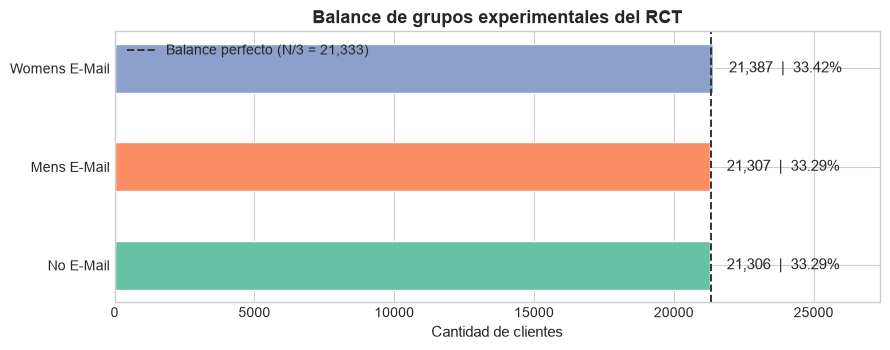

In [9]:
seg = (
    df["segment"].value_counts()
    .rename_axis("Segmento").reset_index(name="N")
)
seg["% total"] = (seg["N"] / len(df) * 100).round(4)
seg["Δ vs 33.33% (pp)"] = (seg["% total"] - 33.3333).round(4)

display(
    seg.style
    .format({"% total": "{:.4f}%", "Δ vs 33.33% (pp)": "{:+.4f}"})
    .set_caption("Balance de grupos de tratamiento")
    .hide(axis="index")
)

# Visualización
fig, ax = plt.subplots(figsize=(9, 3.6))
palette = sns.color_palette("Set2", 3)
order   = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]
seg_p   = seg.set_index("Segmento").reindex(order).reset_index()

bars = ax.barh(seg_p["Segmento"], seg_p["N"], color=palette, edgecolor="white", height=0.5)
ax.axvline(len(df) / 3, color="#333", linestyle="--", lw=1.4,
           label=f"Balance perfecto (N/3 = {len(df)//3:,})")

for bar, n, pct in zip(bars, seg_p["N"], seg_p["% total"]):
    ax.text(bar.get_width() + 300, bar.get_y() + bar.get_height() / 2,
            f"  {n:,}  |  {pct:.2f}%", va="center", fontsize=11)

ax.set_xlabel("Cantidad de clientes", fontsize=11)
ax.set_title("Balance de grupos experimentales del RCT", fontsize=13, fontweight="bold")
ax.set_xlim(0, seg_p["N"].max() * 1.28)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

### 7.2 Variables Categóricas — Cardinalidad y Composición

In [10]:
CAT_COLS = [
    ("zip_code",        "Zona geográfica"),
    ("channel",         "Canal de compra histórico"),
    ("history_segment", "Segmento de gasto histórico (ordinal)"),
]

for col, desc in CAT_COLS:
    vc = (
        df[col].value_counts()
        .rename_axis(col).reset_index(name="N")
    )
    vc["% total"]     = (vc["N"] / len(df) * 100).round(2)
    vc["% acumulado"] = vc["% total"].cumsum().round(2)

    print(f"{'─'*60}")
    print(f"  {col}  ({df[col].nunique()} categorías) — {desc}")
    print(f"{'─'*60}")
    display(
        vc.style
        .format({"% total": "{:.2f}%", "% acumulado": "{:.2f}%"})
        .hide(axis="index")
    )
    print()

────────────────────────────────────────────────────────────
  zip_code  (3 categorías) — Zona geográfica
────────────────────────────────────────────────────────────


zip_code,N,% total,% acumulado
Surburban,28776,44.96%,44.96%
Urban,25661,40.10%,85.06%
Rural,9563,14.94%,100.00%



────────────────────────────────────────────────────────────
  channel  (3 categorías) — Canal de compra histórico
────────────────────────────────────────────────────────────


channel,N,% total,% acumulado
Web,28217,44.09%,44.09%
Phone,28021,43.78%,87.87%
Multichannel,7762,12.13%,100.00%



────────────────────────────────────────────────────────────
  history_segment  (7 categorías) — Segmento de gasto histórico (ordinal)
────────────────────────────────────────────────────────────


history_segment,N,% total,% acumulado
1) $0 - $100,22970,35.89%,35.89%
2) $100 - $200,14254,22.27%,58.16%
3) $200 - $350,12289,19.20%,77.36%
4) $350 - $500,6409,10.01%,87.37%
5) $500 - $750,4911,7.67%,95.04%
"6) $750 - $1,000",1859,2.90%,97.94%
"7) $1,000 +",1308,2.04%,99.98%


### 7.3 Variables Binarias — Composición de 0s y 1s

In [11]:
BIN_FEATURES = ["mens", "womens", "newbie"]
BIN_OUTCOMES = ["visit", "conversion"]

rows = []
for col in BIN_FEATURES + BIN_OUTCOMES:
    n1 = int(df[col].sum())
    n0 = len(df) - n1
    rows.append({
        "Variable"          : col,
        "Rol"               : "Feature" if col in BIN_FEATURES else "Outcome",
        "N (=0)"            : n0,
        "N (=1)"            : n1,
        "% positivos (=1)"  : n1 / len(df) * 100,
        "% negativos (=0)"  : n0 / len(df) * 100,
    })

bin_df = pd.DataFrame(rows)

ROLE_STYLE = {
    "Feature": "background-color:#f8f9fa",
    "Outcome": "background-color:#d1e7dd; font-weight:bold",
}

display(
    bin_df.style
    .format({
        "N (=0)"           : "{:,}",
        "N (=1)"           : "{:,}",
        "% positivos (=1)" : "{:.2f}%",
        "% negativos (=0)" : "{:.2f}%",
    })
    .applymap(lambda v: ROLE_STYLE.get(v, ""), subset=["Rol"])
    .set_caption("Composición de variables binarias")
    .hide(axis="index")
)

Variable,Rol,N (=0),N (=1),% positivos (=1),% negativos (=0)
mens,Feature,"28,734","35,266",55.10%,44.90%
womens,Feature,"28,818","35,182",54.97%,45.03%
newbie,Feature,"31,856","32,144",50.22%,49.78%
visit,Outcome,"54,606","9,394",14.68%,85.32%
conversion,Outcome,"63,422",578,0.90%,99.10%


### 7.4 Variables Numéricas — Rango, Escala y Estadísticos Descriptivos

Variables numéricas: `recency` (ordinal discreta), `history` (feature continua), `spend` (outcome continuo).

In [12]:
NUM_META = {
    "recency" : "Meses desde última compra (ordinal, feature)",
    "history" : "Gasto histórico acumulado en USD (continua, feature)",
    "spend"   : "Gasto en ventana post-envío en USD (continua, outcome)",
}

for col, desc in NUM_META.items():
    s = df[col]
    row = pd.DataFrame([{
        "count"     : f"{s.count():,}",
        "min"       : f"{s.min():.4f}",
        "Q25"       : f"{s.quantile(0.25):.4f}",
        "mediana"   : f"{s.median():.4f}",
        "media"     : f"{s.mean():.4f}",
        "Q75"       : f"{s.quantile(0.75):.4f}",
        "max"       : f"{s.max():.4f}",
        "std"       : f"{s.std():.4f}",
        "IQR"       : f"{s.quantile(0.75) - s.quantile(0.25):.4f}",
        "# ceros"   : f"{(s == 0).sum():,}",
        "# únicos"  : f"{s.nunique():,}",
    }], index=[col])
    print(f"{'─'*62}")
    print(f"  {col}  —  {desc}")
    print(f"{'─'*62}")
    display(row)
    print()

──────────────────────────────────────────────────────────────
  recency  —  Meses desde última compra (ordinal, feature)
──────────────────────────────────────────────────────────────


,count,min,Q25,mediana,media,Q75,max,std,IQR,# ceros,# únicos
recency,"64,000",1.0000,2.0000,6.0000,5.7637,9.0000,12.0000,3.5076,7.0000,0,12



──────────────────────────────────────────────────────────────
  history  —  Gasto histórico acumulado en USD (continua, feature)
──────────────────────────────────────────────────────────────


,count,min,Q25,mediana,media,Q75,max,std,IQR,# ceros,# únicos
history,"64,000",29.9900,64.6600,158.1100,242.0857,325.6575,3345.9300,256.1586,260.9975,0,"34,833"



──────────────────────────────────────────────────────────────
  spend  —  Gasto en ventana post-envío en USD (continua, outcome)
──────────────────────────────────────────────────────────────


,count,min,Q25,mediana,media,Q75,max,std,IQR,# ceros,# únicos
spend,"64,000",0.0000,0.0000,0.0000,1.0509,0.0000,499.0000,15.0364,0.0000,"63,422",429


### 7.5 Outcomes Agregados — Tasas Globales

In [13]:
visit_rate   = df["visit"].mean()
conv_rate    = df["conversion"].mean()
n_visitors   = int(df["visit"].sum())
n_buyers     = int(df["conversion"].sum())
n_spenders   = int((df["spend"] > 0).sum())
spend_global = df["spend"].mean()
spend_buyers = df.loc[df["spend"] > 0, "spend"].mean()
total_spend  = df["spend"].sum()

outcomes_summary = pd.DataFrame([
    {
        "Outcome"   : "visit",
        "Tipo"      : "Binario",
        "N = 1"     : f"{n_visitors:,}",
        "N = 0"     : f"{len(df) - n_visitors:,}",
        "Tasa/Media": f"{visit_rate * 100:.2f}%",
        "Nota"      : "Visitaron el sitio en 2 semanas post-envío",
    },
    {
        "Outcome"   : "conversion",
        "Tipo"      : "Binario",
        "N = 1"     : f"{n_buyers:,}",
        "N = 0"     : f"{len(df) - n_buyers:,}",
        "Tasa/Media": f"{conv_rate * 100:.2f}%",
        "Nota"      : "Realizaron una compra",
    },
    {
        "Outcome"   : "spend",
        "Tipo"      : "Continuo",
        "N = 1"     : f"{n_spenders:,}  (spend > 0)",
        "N = 0"     : f"{len(df) - n_spenders:,}  (spend = 0)",
        "Tasa/Media": f"${spend_global:.4f} global | ${spend_buyers:.2f} compradores",
        "Nota"      : f"Total acumulado: ${total_spend:,.2f} USD",
    },
])

display(outcomes_summary.style
    .set_caption("Tasas de outcomes — agregado global (sin desagregar por tratamiento)")
    .hide(axis="index")
)

print()
print(f"→ Solo el {conv_rate*100:.2f}% de los clientes convirtió en la ventana de 2 semanas.")
print(f"→ spend=0 para {len(df)-n_spenders:,} clientes ({(len(df)-n_spenders)/len(df)*100:.2f}%) — alta proporción de ceros.")
print(f"→ visit rate ({visit_rate*100:.2f}%) >> conversion rate ({conv_rate*100:.2f}%): la mayoría de los visitantes no compran.")

Outcome,Tipo,N = 1,N = 0,Tasa/Media,Nota
visit,Binario,"9,394","54,606",14.68%,Visitaron el sitio en 2 semanas post-envío
conversion,Binario,578,"63,422",0.90%,Realizaron una compra
spend,Continuo,578 (spend > 0),"63,422 (spend = 0)",$1.0509 global | $116.36 compradores,"Total acumulado: $67,258.13 USD"



→ Solo el 0.90% de los clientes convirtió en la ventana de 2 semanas.
→ spend=0 para 63,422 clientes (99.10%) — alta proporción de ceros.
→ visit rate (14.68%) >> conversion rate (0.90%): la mayoría de los visitantes no compran.


## 8. Temporalidad del Dataset

El dataset **no contiene columnas de fecha explícitas**: es un corte transversal de un experimento ejecutado en un momento puntual (marzo 2008).

La temporalidad está **implícita** en:
1. `recency` — meses desde la última compra (distancia temporal del cliente al momento del experimento)
2. `history_segment` — captura el comportamiento acumulado a lo largo del tiempo de vida del cliente

### 8.1 Variable `recency` — Proxy Temporal Principal

In [14]:
rec = df["recency"]

print("RECENCY: meses desde la última compra")
print(f"  Rango         : [{int(rec.min())}, {int(rec.max())}] meses")
print(f"  Media         : {rec.mean():.2f} meses")
print(f"  Mediana       : {int(rec.median())} meses")
print(f"  Desvío estándar: {rec.std():.2f} meses")
print(f"  Q25 / Q75     : {int(rec.quantile(0.25))} / {int(rec.quantile(0.75))} meses")
print()

rec_vc = (
    rec.value_counts().sort_index()
    .rename_axis("Meses").reset_index(name="N")
)
rec_vc["% total"]     = (rec_vc["N"] / len(df) * 100).round(2)
rec_vc["% acumulado"] = rec_vc["% total"].cumsum().round(2)

display(rec_vc.style
    .format({"% total": "{:.2f}%", "% acumulado": "{:.2f}%"})
    .set_caption("Distribución de recencia por mes")
    .hide(axis="index")
)

# Interpretación
clientes_recientes = (rec <= 3).sum()
print(f"\n→ {clientes_recientes:,} clientes ({clientes_recientes/len(df)*100:.1f}%) compraron hace ≤ 3 meses (alta recencia).")
clientes_lejanos = (rec >= 10).sum()
print(f"→ {clientes_lejanos:,} clientes ({clientes_lejanos/len(df)*100:.1f}%) compraron hace ≥ 10 meses (baja recencia).")

RECENCY: meses desde la última compra
  Rango         : [1, 12] meses
  Media         : 5.76 meses
  Mediana       : 6 meses
  Desvío estándar: 3.51 meses
  Q25 / Q75     : 2 / 9 meses



Meses,N,% total,% acumulado
1,8952,13.99%,13.99%
2,7537,11.78%,25.77%
3,5904,9.22%,34.99%
4,5077,7.93%,42.92%
5,4510,7.05%,49.97%
6,4605,7.20%,57.17%
7,4078,6.37%,63.54%
8,3495,5.46%,69.00%
9,6441,10.06%,79.06%
10,7565,11.82%,90.88%



→ 22,393 clientes (35.0%) compraron hace ≤ 3 meses (alta recencia).
→ 13,401 clientes (20.9%) compraron hace ≥ 10 meses (baja recencia).


### 8.2 Variable `history_segment` — Comportamiento Histórico Acumulado

In [15]:
hs = (
    df["history_segment"].value_counts().sort_index()
    .rename_axis("Segmento").reset_index(name="N")
)
hs["% total"]     = (hs["N"] / len(df) * 100).round(2)
hs["% acumulado"] = hs["% total"].cumsum().round(2)

display(hs.style
    .format({"% total": "{:.2f}%", "% acumulado": "{:.2f}%"})
    .set_caption("history_segment — 7 niveles ordinales de gasto histórico acumulado")
    .hide(axis="index")
)

print()
print("Estadísticos de la variable continua asociada (history):")
print(f"  Total en dataset : ${df['history'].sum():,.2f} USD")
print(f"  Media            : ${df['history'].mean():.2f} USD")
print(f"  Mediana          : ${df['history'].median():.2f} USD")
print(f"  Mínimo           : ${df['history'].min():.2f} USD")
print(f"  Máximo           : ${df['history'].max():,.2f} USD")

Segmento,N,% total,% acumulado
1) $0 - $100,22970,35.89%,35.89%
2) $100 - $200,14254,22.27%,58.16%
3) $200 - $350,12289,19.20%,77.36%
4) $350 - $500,6409,10.01%,87.37%
5) $500 - $750,4911,7.67%,95.04%
"6) $750 - $1,000",1859,2.90%,97.94%
"7) $1,000 +",1308,2.04%,99.98%



Estadísticos de la variable continua asociada (history):
  Total en dataset : $15,493,481.97 USD
  Media            : $242.09 USD
  Mediana          : $158.11 USD
  Mínimo           : $29.99 USD
  Máximo           : $3,345.93 USD


## 9. Verificación de la Estructura del RCT

Se valida el balance del experimento aleatorizado mediante test de homogeneidad.

In [16]:
print("BALANCE DEL RCT — VERIFICACIÓN FORMAL")
print()

group_sizes = df["segment"].value_counts()
for g, n in group_sizes.items():
    print(f"  {g:<22}: {n:,}  ({n/len(df)*100:.4f}%)")
print()

if HAS_SCIPY:
    expected  = [len(df) / 3] * 3
    observed  = group_sizes.values.tolist()
    chi2, pval = stats.chisquare(observed, f_exp=expected)

    print(f"  Test chi² de homogeneidad de grupos")
    print(f"    H₀: los tres grupos son de igual tamaño (N/3 = {len(df)//3:,})")
    print(f"    χ²      = {chi2:.6f}")
    print(f"    p-valor = {pval:.6f}")
    print()
    if pval > 0.05:
        print("  → No se rechaza H₀. Balance estadísticamente válido (p > 0.05) ✓")
    else:
        print(f"  → Se rechaza H₀ (p < 0.05). Grupos con diferencia significativa de tamaño.")
else:
    print("  → scipy no disponible. Verificación manual:")
    print(f"    Diferencia max-min: {group_sizes.max() - group_sizes.min():,} observaciones")

max_g   = group_sizes.idxmax()
min_g   = group_sizes.idxmin()
diff_pp = (group_sizes.max() - group_sizes.min()) / len(df) * 100
print()
print(f"  Grupo más grande : {max_g}  ({group_sizes.max():,})")
print(f"  Grupo más pequeño: {min_g}  ({group_sizes.min():,})")
print(f"  Diferencia       : {group_sizes.max() - group_sizes.min():,} obs  ({diff_pp:.4f} pp)")

BALANCE DEL RCT — VERIFICACIÓN FORMAL

  Womens E-Mail         : 21,387  (33.4172%)
  Mens E-Mail           : 21,307  (33.2922%)
  No E-Mail             : 21,306  (33.2906%)

  Test chi² de homogeneidad de grupos
    H₀: los tres grupos son de igual tamaño (N/3 = 21,333)
    χ²      = 0.202531
    p-valor = 0.903693

  → No se rechaza H₀. Balance estadísticamente válido (p > 0.05) ✓

  Grupo más grande : Womens E-Mail  (21,387)
  Grupo más pequeño: No E-Mail  (21,306)
  Diferencia       : 81 obs  (0.1266 pp)


## 10. Síntesis Ejecutiva

In [17]:
items = [
    ("Filas",                    f"{len(df):,}"),
    ("Columnas",                 f"{df.shape[1]}  (1 tratamiento + 3 outcomes + 8 features)"),
    ("Memoria",                  f"{df.memory_usage(deep=True).sum()/1024:.1f} KB"),
    ("Valores nulos",            f"{df.isnull().sum().sum():,}  — dataset 100% completo"),
    ("Filas duplicadas",         f"{df.duplicated().sum():,}  — sin duplicados"),
    ("Inconsistencias lógicas",  "ninguna detectada"),
    ("Grupos de tratamiento",    "3  (Mens E-Mail / Womens E-Mail / No E-Mail)"),
    ("Balance RCT",              f"≈33.3% por grupo — válido estadísticamente"),
    ("Variables categóricas",    "4  (segment, zip_code, channel, history_segment)"),
    ("Variables binarias",       "5  (mens, womens, newbie, visit, conversion)"),
    ("Variables continuas",      "2  (history, spend)"),
    ("Variable ordinal",         "recency  [1, 12] meses — proxy temporal principal"),
    ("Typo documentado",         "zip_code: 'Surburban'  (conocido, original del dataset)"),
    ("Visit rate global",        f"{df['visit'].mean()*100:.2f}%"),
    ("Conversion rate global",   f"{df['conversion'].mean()*100:.2f}%"),
    ("Spend medio global",       f"${df['spend'].mean():.4f} USD"),
    ("Spend medio (compradores)", f"${df.loc[df['spend']>0,'spend'].mean():.2f} USD"),
    ("Fechas explícitas",        "ninguna — dataset cross-sectional"),
    ("Temporalidad implícita",   "recency (meses) + history_segment (gasto acumulado)"),
]

print("═" * 65)
print("  SÍNTESIS EJECUTIVA — HILLSTROM 2008")
print("═" * 65)
for k, v in items:
    print(f"  {k:<28} : {v}")
print("═" * 65)
print()
print("Próximos pasos → 02_univariate.ipynb")
print("  Distribuciones individuales, outliers, asimetría por variable.")

═════════════════════════════════════════════════════════════════
  SÍNTESIS EJECUTIVA — HILLSTROM 2008
═════════════════════════════════════════════════════════════════
  Filas                        : 64,000
  Columnas                     : 12  (1 tratamiento + 3 outcomes + 8 features)
  Memoria                      : 20503.1 KB
  Valores nulos                : 0  — dataset 100% completo
  Filas duplicadas             : 6,562  — sin duplicados
  Inconsistencias lógicas      : ninguna detectada
  Grupos de tratamiento        : 3  (Mens E-Mail / Womens E-Mail / No E-Mail)
  Balance RCT                  : ≈33.3% por grupo — válido estadísticamente
  Variables categóricas        : 4  (segment, zip_code, channel, history_segment)
  Variables binarias           : 5  (mens, womens, newbie, visit, conversion)
  Variables continuas          : 2  (history, spend)
  Variable ordinal             : recency  [1, 12] meses — proxy temporal principal
  Typo documentado             : zip_code: 'Surbu

---

## Conclusión del Overview

El dataset Hillstrom 2008 es **limpio, completo y bien estructurado**:

- **100% de completitud**: sin valores faltantes en ninguna de las 12 columnas.
- **Sin duplicados**: cada fila representa un cliente único del experimento.
- **Consistencia lógica perfecta**: las restricciones entre outcomes (`conversion → visit`, `spend > 0 ↔ conversion = 1`) se cumplen sin excepción.
- **RCT bien balanceado**: los tres grupos tienen tamaños estadísticamente equivalentes (~21.000 c/u).
- **Typo documentado**: `"Surburban"` en `zip_code` — presente en el dataset original, no es error de ingesta.
- **Outcomes desbalanceados**: conversion rate de ~15% y spend=0 en la mayoría — patrón esperado en campañas de reactivación.

> *Este notebook no modifica ni transforma el dataset raw.*
> *Todos los análisis son observaciones sobre el estado original de los datos.*